# Chapter 3 — Dimensionality Reduction Techniques

> Reproduction notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025).

## Chapter Summary

The chapter uses a soup analogy: the right *ingredients* (features) matter more than simply adding more. Dimensionality reduction keeps the information while reducing the number of features.

| Technique | Type | Goal | Best for |
|---|---|---|---|
| **PCA** | Unsupervised, linear | Maximise retained variance | Exploration, noise reduction, feature extraction |
| **LDA** | Supervised, linear | Maximise class separability | Classification tasks |
| **t-SNE** | Unsupervised, non-linear | Preserve local neighbourhoods in 2D/3D | Visualisation only |

Reasons to reduce dimensions: simpler data, lower computational cost, less overfitting, and the ability to visualise. The trade-offs are possible information loss, accuracy loss and underfitting if too much is removed.

## 1. Introduction to dimensionality reduction

**Theory.** Reduction methods fall into two families:

* **Feature selection** keeps a *subset* of the original features: *filter* (statistics such as correlation), *wrapper* (e.g. RFE), *embedded* (e.g. Lasso).
* **Feature extraction** builds *new* features in a lower-dimensional space: PCA, LDA, t-SNE.

General workflow: assess dimensionality → choose selection or extraction → apply it with scikit-learn → compare model performance with and without it.

## 2. Transforming datasets with PCA

**Theory.** PCA finds orthogonal directions (*principal components*) along which the data varies the most, then projects the data onto the first few.

Steps behind `PCA`:
1. **Standardize** the data (PCA is sensitive to variance, so features need the same scale).
2. Compute the **covariance matrix**.
3. Compute **eigenvalues / eigenvectors**: eigenvectors = directions; eigenvalues = variance captured.
4. **Select** the top components.
5. **Project** the data onto them.

`explained_variance_ratio_` tells how much of the total variance each component keeps.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
import warnings

np.random.seed(2024)
warnings.simplefilter(action='ignore', category=FutureWarning)

wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target
display(df_wine.head(10))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


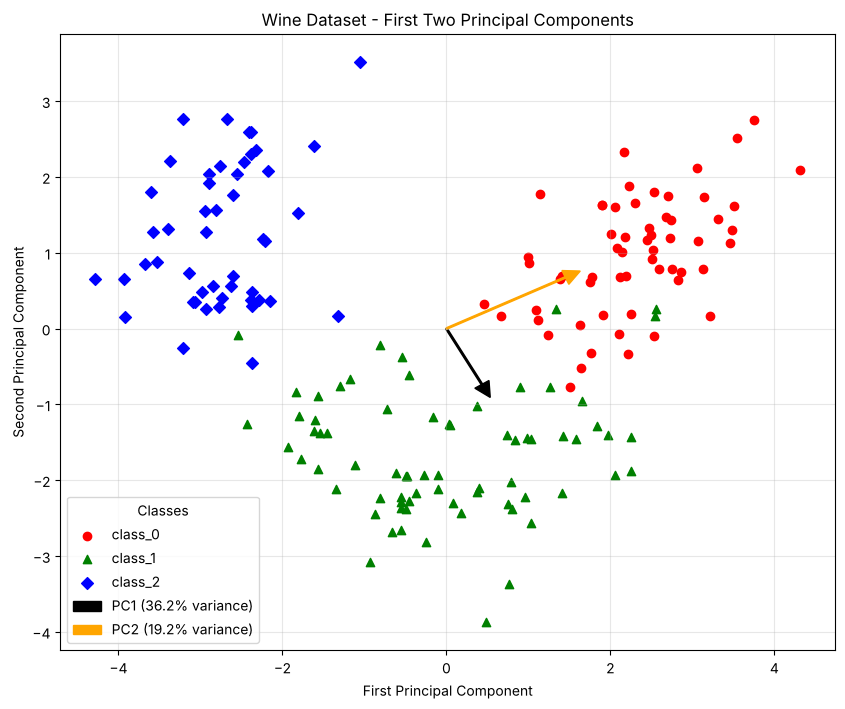

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),      # Always scale before PCA
    ('pca', PCA(n_components=2)),      # Reduce to 2 dimensions
])
X_pca = pca_pipeline.fit_transform(df_wine)

plt.figure(figsize=(10, 8))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(
        X_pca[target_wine == i, 0],
        X_pca[target_wine == i, 1],
        c=color, marker=shape,
        label=wine.target_names[i],
    )

# Plot the principal component directions as vectors
pca = pca_pipeline.named_steps['pca']
origin = np.zeros(2)
arrow_colors = ['black', 'orange']
scaling = 3
for i, (component, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(
        origin[0], origin[1],
        component[0] * scaling, component[1] * scaling,
        color=arrow_colors[i], width=0.02,
        head_width=0.2, head_length=0.2,
        label=f'PC{i+1} ({ratio:.1%} variance)',
    )

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title="Classes")   # (the book has curly quotes here, which is a typo)
plt.grid(True, alpha=0.3)
plt.show()

**How it works — explained variance.** The bar chart below shows how much information each component retains. The book reports that the first two components explain **55.41 %** of the variance of the wine data.

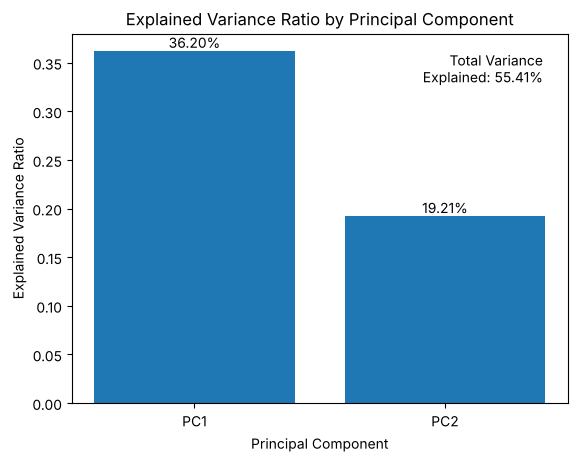

In [3]:
pca = pca_pipeline.named_steps['pca']
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.sum(explained_variance_ratio)

fig, ax = plt.subplots()
x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2., height,
            f'{height:.2%}', ha='center', va='bottom')

ax.text(0.95, 0.95, f'Total Variance\nExplained: {cumulative_variance:.2%}',
        transform=ax.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_xticks(x)
ax.set_xticklabels(['PC1', 'PC2'])
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Explained Variance Ratio by Principal Component')
plt.show()

**Before / after PCA on just two features** (the book's Figure 3.4; its code lives in the book's notebook, so this is my own reproduction of the idea): top row = two standardized original features, bottom row = the same data rotated onto PC1/PC2.

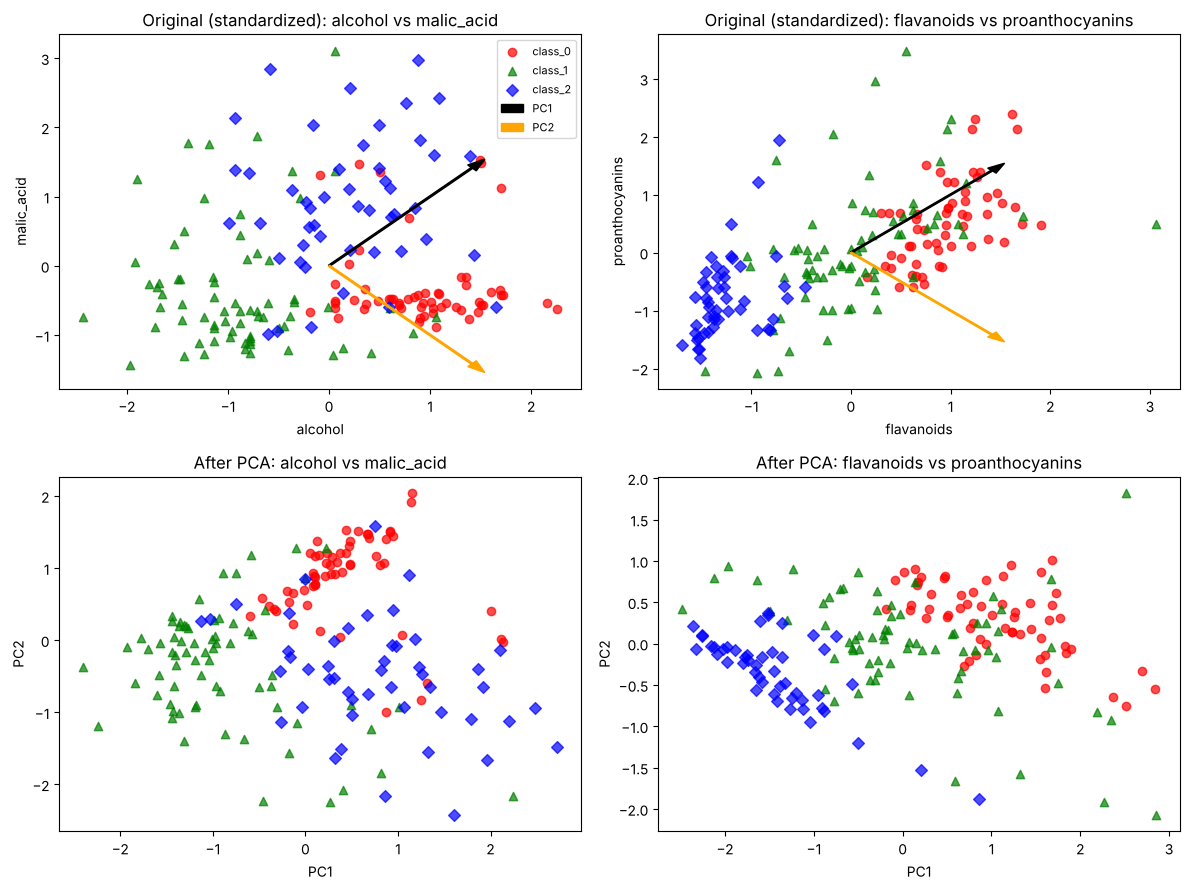

In [4]:
pairs = [("alcohol", "malic_acid"), ("flavanoids", "proanthocyanins")]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for col, (f1, f2) in enumerate(pairs):
    Xp = StandardScaler().fit_transform(df_wine[[f1, f2]])
    p = PCA(n_components=2).fit(Xp)
    Xt = p.transform(Xp)

    for i, (shape, color) in enumerate(zip(shapes, colors)):
        axes[0, col].scatter(Xp[target_wine == i, 0], Xp[target_wine == i, 1],
                             c=color, marker=shape, alpha=.7, label=wine.target_names[i])
        axes[1, col].scatter(Xt[target_wine == i, 0], Xt[target_wine == i, 1],
                             c=color, marker=shape, alpha=.7, label=wine.target_names[i])
    axes[0, col].set_title(f"Original (standardized): {f1} vs {f2}")
    axes[0, col].set_xlabel(f1); axes[0, col].set_ylabel(f2)
    for j, comp in enumerate(p.components_):
        axes[0, col].arrow(0, 0, comp[0]*2, comp[1]*2, color=['black', 'orange'][j],
                           width=0.02, head_width=0.12, label=f"PC{j+1}")
    axes[1, col].set_title(f"After PCA: {f1} vs {f2}")
    axes[1, col].set_xlabel("PC1"); axes[1, col].set_ylabel("PC2")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Maximising class separability with LDA

**Theory.** Linear Discriminant Analysis is **supervised**: it uses class labels to find axes that *maximise the distance between class means* while *minimising the variance within each class*. It assumes each class is Gaussian with a common covariance matrix (another reason to standardize).

The maximum number of components is $\min(n\_features,\ n\_classes-1)$ — for the wine data (3 classes) that is 2.

**PCA vs LDA**

| | PCA | LDA |
|---|---|---|
| Learning type | Unsupervised | Supervised |
| Objective | Keep maximum variance | Maximise class separation |
| Output | Orthogonal principal components | Linear discriminants |
| Use case | Exploration, feature extraction | Classification |

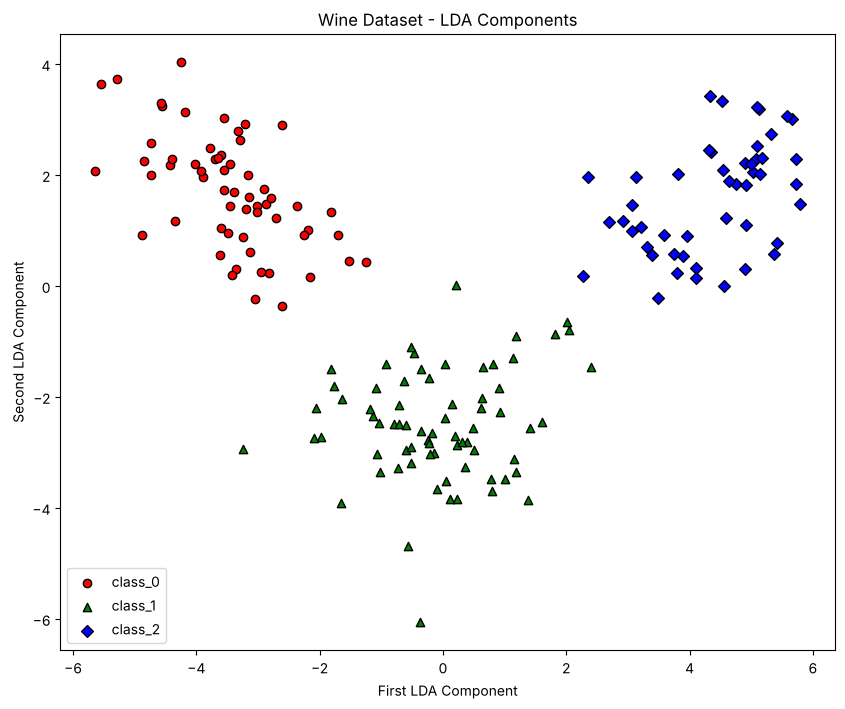

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X_wine, y_wine = wine.data, wine.target

lda_pipeline_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2)),  # min(n_features, n_classes - 1) = 2
])
X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)

plt.figure(figsize=(10, 8))
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
                c=color, marker=shape, edgecolor='black',
                label=wine.target_names[i])
plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.show()

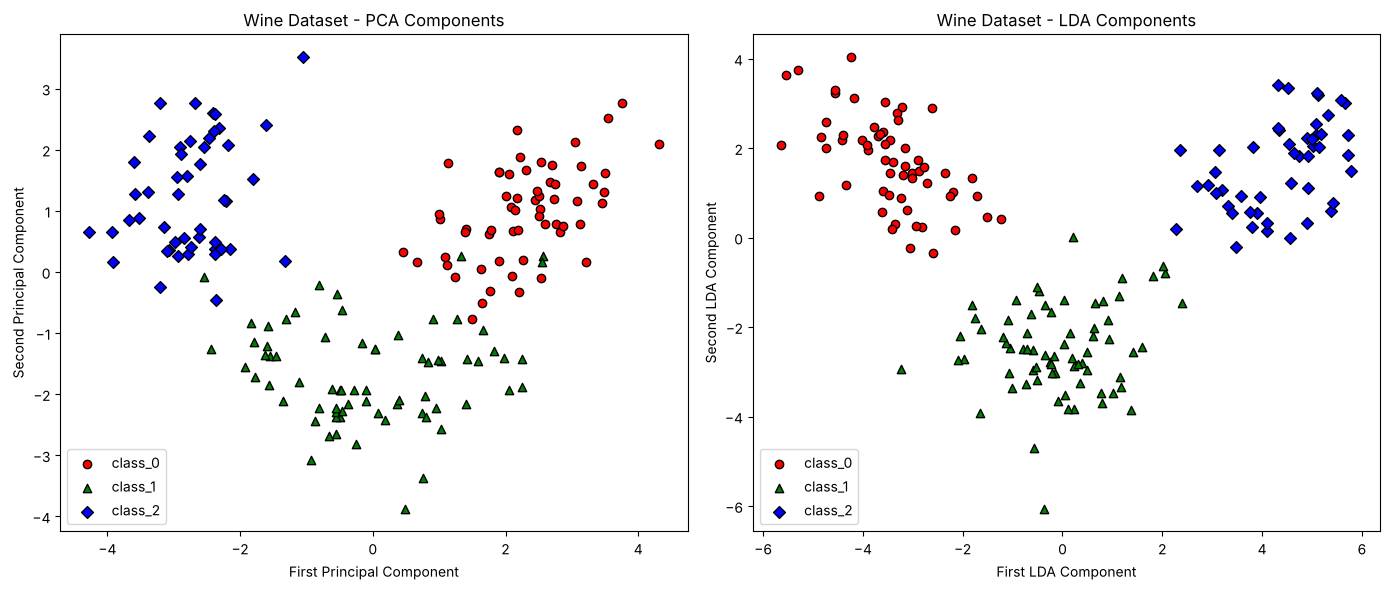

In [6]:
# Side-by-side comparison of PCA and LDA
plt.figure(figsize=(14, 6))

plt.subplot(121)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, marker=shape,
                edgecolor='black', label=wine.target_names[i])
plt.xlabel('First Principal Component'); plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - PCA Components'); plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1], c=color, marker=shape,
                edgecolor='black', label=wine.target_names[i])
plt.xlabel('First LDA Component'); plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components'); plt.legend()

plt.tight_layout()
plt.show()

**Takeaway.** Class separation looks sharper with LDA — partly because it *uses* the labels, which PCA never sees.

## 4. t-SNE and data visualisation

**Theory.** t-SNE (t-Distributed Stochastic Neighbor Embedding) is a **non-linear** method for visualising high-dimensional data in 2D/3D:

1. Compute **pairwise similarities** in high dimensions (turned into conditional probabilities; similar points get high probability).
2. Find a **low-dimensional map** whose similarities match as closely as possible.
3. The result shows **clusters** of similar points.

It preserves *local* structure but distances between far-apart clusters are not meaningful, it is computationally heavy, and it is meant for visualisation rather than as model input.

Dataset: the *digits* data (8×8 images of handwritten digits 0–9, from the UCI ML repository).

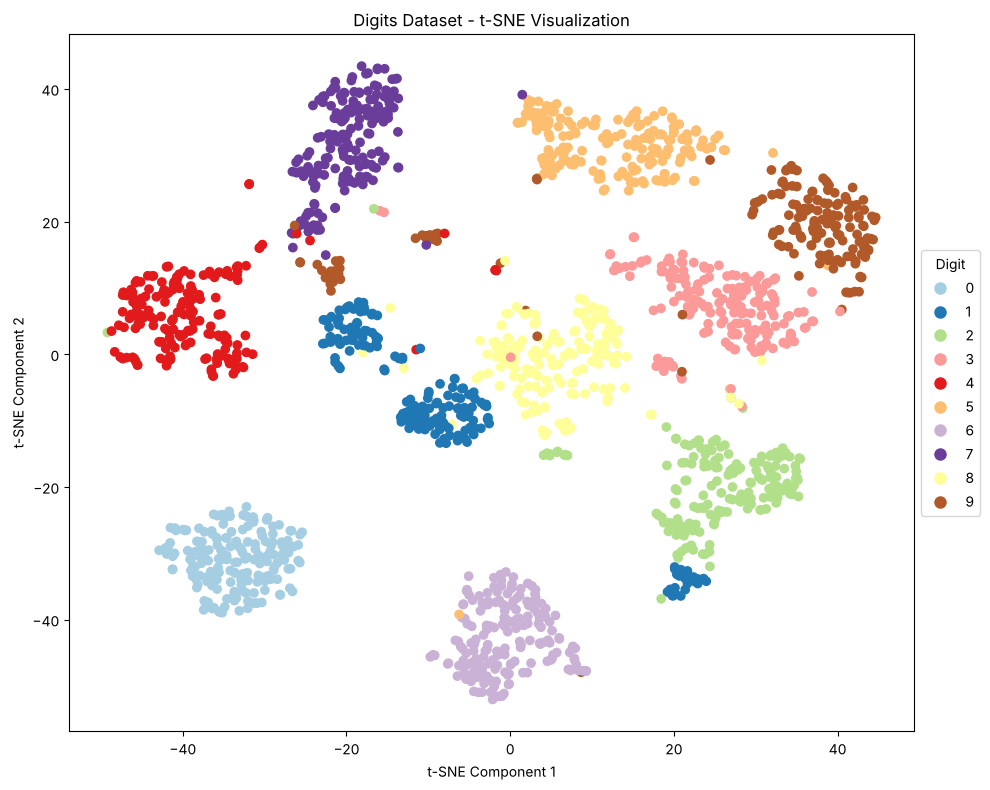

In [7]:
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE

digits = load_digits()

tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024)),
])
X_tsne = tsne_pipeline.fit_transform(digits.data)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=digits.target, cmap='Paired')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('Digits Dataset - t-SNE Visualization')

legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=plt.cm.Paired(i / 9),
               label=str(i), markersize=10)
    for i in range(10)
]
plt.legend(handles=legend_elements, title='Digit',
           loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Digits such as 4, 7 and 9 (written similarly) land near each other, while 0 is isolated — the map reflects how similar the digits look.

## 5. Selecting the right technique

**Decision guide (book, Figure 3.8 and Table 3.1)**

* *Supervised vs unsupervised*: labelled data + class separability → **LDA**; unlabeled + keep variance → **PCA**; visualisation → **t-SNE**.
* *Variance vs class separability*: variance → PCA; separation → LDA; complex cluster structure → t-SNE.
* *Extraction vs visualisation*: PCA/LDA for model input, t-SNE for plots.
* *Efficiency*: PCA is fast; LDA needs class means and covariances; t-SNE is slow on big data.
* *Interpretability*: PCA components are linear mixes (hard to read); LDA discriminants relate to class separation; t-SNE is visual only.

If unsure, combine them (e.g. PCA first, then t-SNE) and evaluate with model metrics or clarity of the plot.

## 6. Impact on model performance (trade-offs)

* **Complexity vs interpretability** – fewer features = simpler model, but you risk losing information.
* **Training time vs accuracy** – faster training, potential accuracy loss.
* **Overfitting vs generalisation** – removing noise helps generalisation, but removing too much causes underfitting.

## 7. Practical exercises

The book lists the implementation steps only (the code is in its GitHub repo). Below are my implementations of both exercises.

### Exercise 1 — PCA with logistic regression (Iris)
Steps: load libraries → split data → pipeline **without** PCA → pipeline **with** PCA → fit and evaluate both → print results.

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=2024)

# Pipeline without PCA
pipe_no_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000)),
])

# Pipeline with PCA (4 features -> 2 components)
pipe_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('clf', LogisticRegression(max_iter=1000)),
])

for name, pipe in [("Without PCA (4 features)", pipe_no_pca), ("With PCA (2 components)", pipe_pca)]:
    pipe.fit(X_train, y_train)
    acc = accuracy_score(y_test, pipe.predict(X_test))
    print(f"{name:28s} accuracy = {acc:.3f}")

Without PCA (4 features)     accuracy = 0.956
With PCA (2 components)      accuracy = 0.867


### Exercise 2 — t-SNE for visualisation (digits) with K-means
Steps: load libraries → apply K-means → side-by-side plots → plot using true labels → plot using cluster labels.

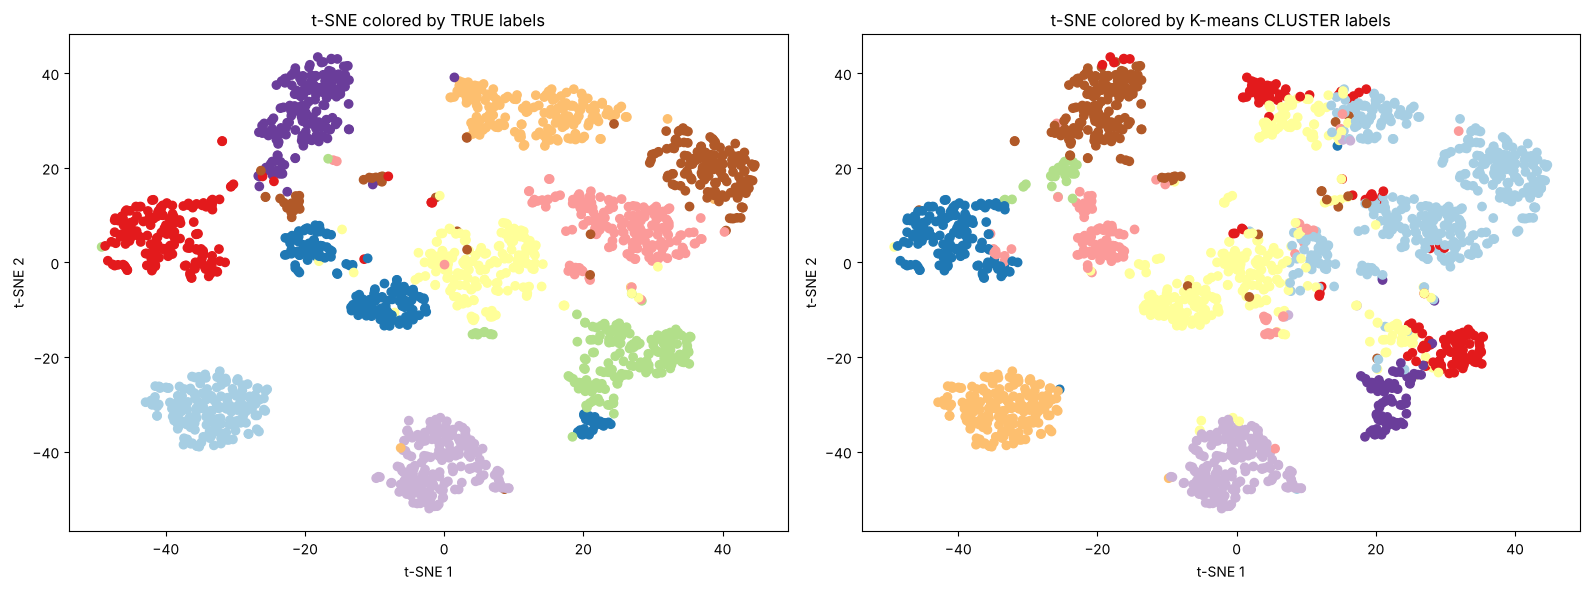

In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=10, random_state=2024, n_init=10)
cluster_labels = kmeans.fit_predict(StandardScaler().fit_transform(digits.data))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired')
axes[0].set_title("t-SNE colored by TRUE labels")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap='Paired')
axes[1].set_title("t-SNE colored by K-means CLUSTER labels")
for ax in axes:
    ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

---
### Chapter 3 key takeaways
1. **PCA** = unsupervised, keeps variance; scale first. **LDA** = supervised, maximises class separation. **t-SNE** = non-linear, for visualisation.
2. Choose by goal (model performance vs. visualisation), label availability, data size and interpretability needs.
3. Always compare model performance before/after reduction — you trade simplicity and speed against potential information loss.